In [1]:
from importlib.metadata import version
import tiktoken
print("tiktoken version:", version("tiktoken"))

tiktoken version: 0.14.0


In [2]:
import torch
import torch.nn as nn

In [3]:
tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:

# import pyarrow.parquet as pq
# from pathlib import Path
# import tiktoken
# import numpy as np

# DATA_DIR = Path(
#     r"D:\built a llm from scratch 124million parameters\fineweb-edu\pretraining"
# )

# TOKEN_FILE = DATA_DIR.parent / "fineweb_tokens.bin"

# # Test with 1 million tokens first.
# # Change to 3_000_000_000 after the test works.
# TARGET_TOKENS = 3_003_000_000

# # Your existing GPT-2 BPE tokenizer
# tokenizer = tiktoken.get_encoding("gpt2")

# parquet_files = sorted(DATA_DIR.rglob("*.parquet"))

# if not parquet_files:
#     raise FileNotFoundError("No Parquet files found!")

# total_tokens = 0
# token_buffer = []
# WRITE_CHUNK_SIZE = 1_000_000

# # Keep a small text sample so your earlier demo cells still work.
# raw_text_parts = []
# sample_chars = 0
# DEMO_TEXT_CHARS = 100_000

# # "wb" creates a new file or overwrites the existing token file.
# with open(TOKEN_FILE, "wb") as output_file:

#     stop = False

#     for file_path in parquet_files:
#         print("Reading:", file_path.name)

#         parquet_file = pq.ParquetFile(file_path)

#         for batch in parquet_file.iter_batches(
#             batch_size=1000,
#             columns=["text"]
#         ):
#             texts = batch.column("text").to_pylist()

#             for text in texts:
#                 if not isinstance(text, str) or not text.strip():
#                     continue

#                 # Keep only a small raw-text sample for demonstrations.
#                 if sample_chars < DEMO_TEXT_CHARS:
#                     piece = text[:DEMO_TEXT_CHARS - sample_chars]
#                     raw_text_parts.append(piece)
#                     sample_chars += len(piece)

#                 # Use the GPT-2 BPE tokenizer on this document.
#                 ids = tokenizer.encode(
#                     text,
#                     allowed_special={"<|endoftext|>"},
#                     disallowed_special=()
#                 )

#                 # Mark the document's end.
#                 ids.append(tokenizer.eot_token)

#                 # Do not exceed the requested token count.
#                 remaining = TARGET_TOKENS - total_tokens
#                 ids = ids[:remaining]

#                 token_buffer.extend(ids)
#                 total_tokens += len(ids)

#                 # Save tokens incrementally to the SSD.
#                 if len(token_buffer) >= WRITE_CHUNK_SIZE:
#                     np.asarray(
#                         token_buffer, dtype=np.uint16
#                     ).tofile(output_file)
#                     token_buffer.clear()

#                 if total_tokens >= TARGET_TOKENS:
#                     stop = True
#                     break

#             if stop:
#                 break

#         if stop:
#             break

#     # Save the leftover tokens.
#     if token_buffer:
#         np.asarray(
#             token_buffer, dtype=np.uint16
#         ).tofile(output_file)

# # This is only a small sample, not the entire dataset.
# raw_text = "\n\n".join(raw_text_parts)

# print("Tokens saved:", f"{total_tokens:,}")
# print("Token file:", TOKEN_FILE)
# # print("File size:", f"{TOKEN_FILE.stat().st_size / 1_000_000:.2f} MB")
# # print("Demo text characters:", len(raw_text))


In [ ]:
import pyarrow.parquet as pq
from pathlib import Path
import numpy as np

DATA_DIR = Path(r"D:\built a llm from scratch 124million parameters\fineweb-edu\pretraining")
TOKEN_FILE = DATA_DIR.parent / "fineweb_tokens.bin"

parquet_files = sorted(DATA_DIR.rglob("*.parquet"))
parts, n = [], 0
for rb in pq.ParquetFile(parquet_files[0]).iter_batches(batch_size=100, columns=["text"]):
    for text in rb.column("text").to_pylist():
        if isinstance(text, str) and text.strip():
            piece = text[:100_000 - n]
            parts.append(piece)
            n += len(piece)
        if n >= 100_000:
            break
    if n >= 100_000:
        break
raw_text = "\n\n".join(parts)
print("Token file:", TOKEN_FILE.exists(), f"{TOKEN_FILE.stat().st_size / 1e9:.2f} GB")

Token file: True 6.01 GB



Byte pair encoding

In [ ]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

In [ ]:
strings = tokenizer.decode(integers)
print(strings)

In [ ]:
enc_text = tokenizer.encode(raw_text, allowed_special={"<|endoftext|>"})
print(len(enc_text))

In [9]:
enc_sample = enc_text[50:]

In [ ]:
context_size = 4        
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:      {y}")

In [ ]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print("input",context, "---->", "output",desired)

In [ ]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

In [13]:
import torch
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt)

        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1:i + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]
    
    
    
    
    
    
    
    
    
    
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                        stride=128, shuffle=True, drop_last=True,
                        num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

batch size more than 1 

Let’s see how the token ID to embedding vector conversion works with a hands-on
example. Suppose we have the following four input tokens with IDs 2, 3, 5, and 1

# embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [14]:
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [15]:
inputs = torch.tensor([[40, 367, 2885, 1464]])

In [ ]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)


positional embedding

In [17]:
max_length =4

In [ ]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

In [ ]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

In [20]:
d_in = inputs.shape[1]     
d_out = 2

In [21]:
import torch
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your    
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts  

   [0.22, 0.58, 0.33], # with    
   [0.77, 0.25, 0.10], # one     
   [0.05, 0.80, 0.55]] # step    
)


all of this self attention in a class

multi head in parallel


In [22]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out,
                 context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        values = values.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        queries = queries.view(
            b, num_tokens, self.num_heads, self.head_dim
        )

        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        context_vec = torch.nn.functional.scaled_dot_product_attention(
            queries, keys, values,
            dropout_p=self.dropout.p if self.training else 0.0,
            is_causal=True
        ).transpose(1, 2)

        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out
        )

        context_vec = self.out_proj(context_vec)

        return context_vec

Implementing
a GPT model from
scratch to generate text

In [ ]:
GPT_CONFIG_163M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,           # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
}

current code is a working structural prototype, not a working GPT language model. It lets you verify that the components connect and the tensor shapes work before you implement attention.

layer normalizat6ion like mean=0, var=1

 Let’s
now encapsulate this process in a PyTorch module that we can use in the GPT model
later.

In [24]:
# class LayerNorm(nn.Module):
#     def __init__(self, emb_dim):
#         super().__init__()
#         self.eps = 1e-5
#         self.scale = nn.Parameter(torch.ones(emb_dim))
#         self.shift = nn.Parameter(torch.zeros(emb_dim))
#     def forward(self, x):
#         mean = x.mean(dim=-1, keepdim=True)
#         var = x.var(dim=-1, keepdim=True, unbiased=False)
#         norm_x = (x - mean) / torch.sqrt(var + self.eps)
#         return self.scale * norm_x + self.shift

In [25]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))
    def forward(self, x):
        return torch.nn.functional.layer_norm(
            x, self.scale.shape, self.scale, self.shift, self.eps
        )


Implementing a feed forward network 
with GELU activations

In [26]:
# class GELU(nn.Module):
#     def __init__(self):
#         super().__init__()
#     def forward(self, x):
#         return 0.5 * x * (1 + torch.tanh(
#             torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
#             (x + 0.044715 * torch.pow(x, 3))
# ))


In [27]:
class GELU(nn.Module):
    def forward(self, x):
        return torch.nn.functional.gelu(x, approximate="tanh")

 A feed forward neural network module

In [28]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
)
    def forward(self, x):
        return self.layers(x)

A neural network to illustrate shortcut connections

In [29]:


def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])

    loss = nn.MSELoss()
    loss = loss(output, target)

    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")


Connecting attention and linear layers 
in a transformer block

In [30]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut
        return x

In [ ]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768)                  
block = TransformerBlock(GPT_CONFIG_163M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

The GPT model architecture implementation

In [32]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)

        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)

        logits = self.out_head(x)
        return logits

In [118]:
batch = torch.tensor([
       [6109, 3626, 6100, 345],
       [6109, 1110, 6622, 257],
   ])

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_163M)
out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

In [120]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


A function for the GPT model to generate text

In [53]:
def generate_text_simple(model, idx,
                         max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [ ]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)   
print("encoded_tensor.shape:", encoded_tensor.shape)

In [ ]:
model.eval()

out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_163M["context_length"]
)

print("Output:", out)
print("Output length:", len(out[0]))

In [124]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue


Pretraining
on unlabeled data

using gpt to generate text 

In [ ]:
import torch

GPT_CONFIG_163M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_163M)
model.eval()

Utility functions for text to token ID conversion

In [ ]:
import tiktoken


def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(
        text, allowed_special={'<|endoftext|>'}
    )
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)
    return tokenizer.decode(flat.tolist())


start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_163M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Calculating the text generation loss

In [127]:
# Load the FineWeb token file without loading all tokens into RAM

TOKEN_FILE = DATA_DIR.parent / "fineweb_tokens.bin"

token_ids = np.memmap(
    TOKEN_FILE,
    dtype=np.uint16,
    mode="r"
)

total_tokens = len(token_ids)

print("Total tokens:", f"{total_tokens:,}")
print("Token file size:",
      f"{TOKEN_FILE.stat().st_size / 1_000_000_000:.2f} GB")

if total_tokens < 3_003_000_000:
    raise ValueError(
        "The token file is incomplete. Finish Cell 2 first."
    )

Total tokens: 3,003,000,000
Token file size: 6.01 GB


In [128]:
# Define how many tokens are for training and validation

TRAIN_TOKENS = 3_000_000_000
VAL_TOKENS = 3_000_000

required_tokens = TRAIN_TOKENS + VAL_TOKENS

if total_tokens < required_tokens:
    raise ValueError(
        f"Need {required_tokens:,} tokens, "
        f"but only {total_tokens:,} are available."
    )

print("Training tokens:", f"{TRAIN_TOKENS:,}")
print("Validation tokens:", f"{VAL_TOKENS:,}")
print("Total required:", f"{required_tokens:,}")

Training tokens: 3,000,000,000
Validation tokens: 3,000,000
Total required: 3,003,000,000


start_idx and end_idx select which part of the dataset you use.



seq_len determines how many tokens the model processes in each example.



token_ids contains the actual token data.



self is handled automatically by Python.

idx means index of the training example you want to retrieve

The key distinction: When GPT generates text, the final generated sequence includes the original prompt plus new tokens. But during training, target_ids contains the next-token answers aligned with each input position, not the entire prompt again

In [129]:

from torch.utils.data import Dataset
import numpy as np
import torch


class FineWebTokenDataset(Dataset):

    def __init__(self, token_ids, start_idx, end_idx, seq_len):
        self.token_ids = token_ids
        self.start_idx = start_idx
        self.end_idx = min(end_idx, len(token_ids))
        self.seq_len = seq_len

        # Number of complete input-target sequences available
        self.n_samples = max(
            0,
            (self.end_idx - self.start_idx - 1) // self.seq_len
        )

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        start = self.start_idx + idx * self.seq_len

        input_ids = np.asarray(
            self.token_ids[start:start + self.seq_len],
            dtype=np.int64
        ).copy()

        target_ids = np.asarray(
            self.token_ids[start + 1:start + self.seq_len + 1],
            dtype=np.int64
        ).copy()

        return (
            torch.from_numpy(input_ids),
            torch.from_numpy(target_ids)
        )


In [ ]:

from torch.utils.data import DataLoader

torch.manual_seed(123)

# Use your GPT model's context length
sequence_length = GPT_CONFIG_163M["context_length"]

# Create training and validation datasets from the token file
train_dataset = FineWebTokenDataset(
    token_ids,
    start_idx=0,
    end_idx=TRAIN_TOKENS,
    seq_len=sequence_length
)

val_dataset = FineWebTokenDataset(
    token_ids,
    start_idx=TRAIN_TOKENS,
    end_idx=TRAIN_TOKENS + VAL_TOKENS,
    seq_len=sequence_length
)

# Create DataLoaders
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

print("Training sequences:", f"{len(train_dataset):,}")
print("Validation sequences:", f"{len(val_dataset):,}")
print("Batch size:", BATCH_SIZE)
print("Sequence length:", sequence_length)


Training sequences: 2,929,687
Validation sequences: 2,929
Batch size: 2
Sequence length: 1024


In [131]:

# Check one training batch
train_inputs, train_targets = next(iter(train_loader))

print("Training input shape:", train_inputs.shape)
print("Training target shape:", train_targets.shape)

# Check one validation batch
val_inputs, val_targets = next(iter(val_loader))

print("Validation input shape:", val_inputs.shape)
print("Validation target shape:", val_targets.shape)


Training input shape: torch.Size([2, 1024])
Training target shape: torch.Size([2, 1024])
Validation input shape: torch.Size([2, 1024])
Validation target shape: torch.Size([2, 1024])


In [132]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(
        logits.float().flatten(0, 1), target_batch.flatten()
    )
    return loss

In [133]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )
            total_loss += loss.item()
        else:
            break

    return total_loss / num_batches

In [134]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

with torch.no_grad():
    train_loss = calc_loss_loader(
        train_loader,
        model,
        device,
        num_batches=5
    )

    val_loss = calc_loss_loader(
        val_loader,
        model,
        device,
        num_batches=5
    )

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.99209384918213
Validation loss: 10.995453643798829


In [135]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter
        )
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

In [136]:

from tqdm.auto import tqdm
import time

def train_model_simple(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs,
    eval_freq,
    eval_iter,
    start_context,
    tokenizer,
    checkpoint_freq=10_000
):
    train_losses = []
    val_losses = []
    track_tokens_seen = []

    tokens_seen = 0
    global_step = -1

    total_steps = num_epochs * len(train_loader)
    start_time = time.time()

    progress_bar = tqdm(
        total=total_steps,
        desc="Fine-tuning",
        unit="step"
    )

    for epoch in range(num_epochs):
        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()

            loss = calc_loss_batch(
                input_batch,
                target_batch,
                model,
                device
            )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )
            optimizer.step()

            tokens_seen += input_batch.numel()
            global_step += 1

            progress_bar.update(1)

            elapsed = time.time() - start_time
            completed = global_step + 1
            remaining = (
                elapsed / completed * (total_steps - completed)
                if completed > 0 else 0
            )

            progress_bar.set_postfix({
                "loss": f"{loss.item():.3f}",
                "elapsed": f"{elapsed / 60:.1f}m",
                "remaining": f"{remaining / 60:.1f}m"
            })

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model,
                    train_loader,
                    val_loader,
                    device,
                    eval_iter
                )

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)

                progress_bar.set_postfix({
                    "train_loss": f"{train_loss:.3f}",
                    "val_loss": f"{val_loss:.3f}",
                    "elapsed": f"{elapsed / 60:.1f}m",
                    "remaining": f"{remaining / 60:.1f}m"
                })

            if (
                checkpoint_freq is not None
                and checkpoint_freq > 0
                and global_step > 0
                and global_step % checkpoint_freq == 0
            ):
                torch.save(
                    model.state_dict(),
                    "model.pth"
                )

                torch.save(
                    {
                        "model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "epoch": epoch,
                        "global_step": global_step,
                        "tokens_seen": tokens_seen
                    },
                    "fineweb_training_checkpoint.pth"
                )

                tqdm.write(
                    f"Checkpoint saved at step {global_step}"
                )

        generate_and_print_sample(
            model,
            tokenizer,
            device,
            start_context
        )

    progress_bar.close()

    print(
        f"Training completed in "
        f"{(time.time() - start_time) / 60:.2f} minutes."
    )

    return train_losses, val_losses, track_tokens_seen


In [137]:
# def train_model_simple(
#     model,
#     train_loader,
#     val_loader,
#     optimizer,
#     device,
#     num_epochs,
#     eval_freq,
#     eval_iter,
#     start_context,
#     tokenizer,
#     checkpoint_freq=10_000
# ):
#     train_losses = []
#     val_losses = []
#     track_tokens_seen = []

#     tokens_seen = 0
#     global_step = -1

#     for epoch in range(num_epochs):
#         model.train()

#         for input_batch, target_batch in train_loader:
#             optimizer.zero_grad()

#             loss = calc_loss_batch(
#                 input_batch,
#                 target_batch,
#                 model,
#                 device
#             )

#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#             optimizer.step()

#             tokens_seen += input_batch.numel()
#             global_step += 1

#             if global_step % eval_freq == 0:
#                 train_loss, val_loss = evaluate_model(
#                     model,
#                     train_loader,
#                     val_loader,
#                     device,
#                     eval_iter
#                 )

#                 train_losses.append(train_loss)
#                 val_losses.append(val_loss)
#                 track_tokens_seen.append(tokens_seen)

#                 print(
#                     f"Epoch {epoch + 1} "
#                     f"(Step {global_step:06d}): "
#                     f"Train loss {train_loss:.3f}, "
#                     f"Validation loss {val_loss:.3f}"
#                 )

#             if (
#                 checkpoint_freq is not None
#                 and checkpoint_freq > 0
#                 and global_step > 0
#                 and global_step % checkpoint_freq == 0
#             ):
#                 torch.save(
#                     model.state_dict(),
#                     "model.pth"
#                 )

#                 torch.save(
#                     {
#                         "model_state_dict": model.state_dict(),
#                         "optimizer_state_dict": optimizer.state_dict(),
#                         "epoch": epoch,
#                         "global_step": global_step,
#                         "tokens_seen": tokens_seen
#                     },
#                     "fineweb_training_checkpoint.pth"
#                 )

#                 print(
#                     f"Checkpoint saved at step {global_step}"
#                 )

#         generate_and_print_sample(
#             model,
#             tokenizer,
#             device,
#             start_context
#         )

#     return train_losses, val_losses, track_tokens_seen

In [138]:
import math

def get_lr(update, warmup_updates, total_updates, peak_lr, min_lr):
    if update < warmup_updates:
        return peak_lr * (update + 1) / warmup_updates
    if update >= total_updates:
        return min_lr
    progress = (update - warmup_updates) / (total_updates - warmup_updates)
    return min_lr + 0.5 * (peak_lr - min_lr) * (1 + math.cos(math.pi * progress))


def train_model_accum(
    model, train_loader, val_loader, optimizer, device,
    accum_steps, total_updates, warmup_updates, peak_lr, min_lr,
    eval_freq, eval_iter, start_context, tokenizer,
    checkpoint_freq, start_update=0, tokens_seen=0
):
    train_losses, val_losses, track_tokens_seen = [], [], []
    update = start_update
    micro = 0
    model.train()
    optimizer.zero_grad()

    def save_checkpoint():
        torch.save(model.state_dict(), "model.pth")
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "epoch": 0,
                "global_step": update,
                "tokens_seen": tokens_seen,
                "phase": "accum",
            },
            "fineweb_training_checkpoint.pth",
        )
        print(f"Checkpoint saved at update {update}")

    def report():
        train_loss, val_loss = evaluate_model(
            model, train_loader, val_loader, device, eval_iter
        )
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        track_tokens_seen.append(tokens_seen)
        lr_now = optimizer.param_groups[0]["lr"]
        print(
            f"Update {update:06d} | lr {lr_now:.2e} | "
            f"phase tokens {tokens_seen / 1e9:.3f}B | "
            f"Train loss {train_loss:.3f}, Validation loss {val_loss:.3f}"
        )

    report()
    done = update >= total_updates
    while not done:
        for input_batch, target_batch in train_loader:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            (loss / accum_steps).backward()
            tokens_seen += input_batch.numel()
            micro += 1
            if micro % accum_steps != 0:
                continue

            lr = get_lr(update, warmup_updates, total_updates, peak_lr, min_lr)
            for group in optimizer.param_groups:
                group["lr"] = lr
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            optimizer.zero_grad()
            update += 1

            if update % eval_freq == 0:
                report()
            if update % checkpoint_freq == 0:
                save_checkpoint()
            if update >= total_updates:
                done = True
                break

    save_checkpoint()
    generate_and_print_sample(model, tokenizer, device, start_context)
    return train_losses, val_losses, track_tokens_seen

In [139]:
print("Training sequences:", len(train_dataset))
print("Training batches:", len(train_loader))
print("Validation sequences:", len(val_dataset))
print("Validation batches:", len(val_loader))

Training sequences: 2929687
Training batches: 1464843
Validation sequences: 2929
Validation batches: 1465


In [ ]:

# torch.manual_seed(123)

# model = GPTModel(GPT_CONFIG_163M)
# model.to(device)

# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=0.0004,
#     weight_decay=0.1
# )

# num_epochs = 1

# train_losses, val_losses, tokens_seen = train_model_simple(
#     model,
#     train_loader,
#     val_loader,
#     optimizer,
#     device,
#     num_epochs=num_epochs,
#     eval_freq=5000,
#     eval_iter=5,
#     start_context="Every effort moves you",
#     tokenizer=tokenizer,
#     checkpoint_freq=10_000
# )

# torch.save(model.state_dict(), "model.pth")

# torch.save(
#     {
#         "model_state_dict": model.state_dict(),
#         "optimizer_state_dict": optimizer.state_dict(),
#         "tokens_seen": tokens_seen[-1] if tokens_seen else 0
#     },
#     "fineweb_gpt_final_checkpoint.pth"
# )

# print("Pretraining finished.")
# print("Final model weights saved to model.pth")


In [ ]:
ckpt = torch.load("fineweb_training_checkpoint.pth", map_location=device)
is_accum = ckpt.get("phase") == "accum"
start_update = ckpt["global_step"] if is_accum else 0
phase_tokens = ckpt["tokens_seen"] if is_accum else 0
print("Checkpoint:", "new schedule" if is_accum else "old run", "| starting at update", start_update)

model = GPTModel(GPT_CONFIG_163M)
model.load_state_dict(ckpt["model_state_dict"])
model.to(device)
num_epoches=1

optimizer = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=0.1)
optimizer.load_state_dict(ckpt["optimizer_state_dict"])

torch.manual_seed(start_update + 2024)

train_losses, val_losses, tokens_seen = train_model_accum(
    model, train_loader, val_loader, optimizer, device,
    accum_steps=16,
    total_updates=60_000,
    warmup_updates=200,
    peak_lr=4e-4,
    min_lr=4e-5,
    eval_freq=300,
    eval_iter=50,
    start_context="Every effort moves you",
    tokenizer=tokenizer,
    checkpoint_freq=600,
    start_update=start_update,
    tokens_seen=phase_tokens,
)
print("Pretraining finished.")

Checkpoint: new schedule | starting at update 60000
Update 060000 | lr 4.00e-05 | phase tokens 1.966B | Train loss 3.284, Validation loss 3.318
Checkpoint saved at update 60000
Every effort moves you to the next level. The first step is to get a good understanding of the concept of the word “dictionary”. The dictionary is a collection of words that are used in a dictionary to describe a particular word. The dictionary is
Pretraining finished.


In [ ]:
model.eval()
model.to("cpu")

In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_163M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you to the next level.
The first step is to get a good understanding of the concept of the word “dictionary


Temperature scaling

small example to see


In [149]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

Loading and saving model weights in PyTorch


loading

In [ ]:
# model = GPTModel(GPT_CONFIG_163M)
# model.load_state_dict(torch.load("model.pth", map_location=device))
# model.eval()

saving both the model and the optimizer 

In [151]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)

Then we can restore the model and optimizer states by first loading the saved data via
torch.load and then using the load_state_dict method

In [ ]:
# checkpoint = torch.load("model_and_optimizer.pth", map_location=device)
# model = GPTModel(GPT_CONFIG_163M)
# model.load_state_dict(checkpoint["model_state_dict"])
# optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
# optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# model.train();

Fine-tuning to follow
instructions

Preparing a dataset for supervised instruction 
fine-tuning

In [ ]:

import pyarrow.parquet as pq
from pathlib import Path

FT_DATA_DIR = Path(
    r"D:\built a llm from scratch 124million parameters\fineweb-edu\fine tuning"
)

parquet_files = sorted(FT_DATA_DIR.glob("*.parquet"))

if not parquet_files:
    raise FileNotFoundError(
        f"No Parquet files found in {FT_DATA_DIR}"
    )

data = []

for file_path in parquet_files:
    print("Loading:", file_path.name)

    parquet_file = pq.ParquetFile(file_path)

    for batch in parquet_file.iter_batches(
        batch_size=1000,
        columns=["messages", "source"]
    ):
        for row in batch.to_pylist():
            messages = row.get("messages") or []
            source = row.get("source", "")

            pending_user = None
            assistant_parts = []

            for message in messages:
                role = str(message.get("role", "")).lower()
                content = message.get("content") or ""

                if role in ("user", "human"):
                    if pending_user is not None and assistant_parts:
                        data.append({
                            "instruction": pending_user,
                            "input": "",
                            "output": "\n\n".join(assistant_parts),
                            "source": source
                        })

                    pending_user = content
                    assistant_parts = []

                elif role in ("assistant", "gpt"):
                    if pending_user is not None:
                        assistant_parts.append(content)

            if pending_user is not None and assistant_parts:
                data.append({
                    "instruction": pending_user,
                    "input": "",
                    "output": "\n\n".join(assistant_parts),
                    "source": source
                })

print("Total instruction examples:", len(data))
print("\nExample entry:")
print(data[0] if data else "No usable examples found")


Loading: train-00000-of-00004.parquet
Loading: train-00001-of-00004.parquet
Loading: train-00002-of-00004.parquet
Loading: train-00003-of-00004.parquet
Total instruction examples: 1031866

Example entry:
{'instruction': 'I need you to edit something for me. This is the text I wrote, \n\n"Me and my friends have been waiting for a long time to go back to the movies and catch a movie we been waiting on. Last nite I finely went to go buy tickets and when I got to the movie theater the tickets were sold out, so I was pretty pist. We were all pist. So today we deside if we wanted to go to a game instead, but I dont think we will go to a game now."', 'input': '', 'output': 'Here\'s a revised version of your text with some suggested edits to improve grammar, clarity, and overall flow:\n\n"My friends and I have been waiting a long time to return to the movies and see a film we\'ve been eagerly anticipating. Last night, I finally went to buy tickets, but when I arrived at the theater, they were 

In [154]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'How can I efficiently run and debug the NodeJS code for queries and UI components separately, while keeping them in the same hierarchy and running them independently? The current code is written in TypeScript and handles running queries against databases and caching results in SQLite. The UI component will be built using electron, solidjs, and vite for hot-reloading. Provide a detailed set of steps that involve multiple-step reasoning to help me understand how to call these functions, write queries, execute them, and debug the code using breakpoints, etc. in both the "js_query" and "js_query_ui" folders.', 'input': '', 'output': 'To efficiently run and debug NodeJS code for queries and UI components separately, while keeping them in the same hierarchy and running them independently, you can follow these steps:\n\n1. Create two folders, one for the queries and one for the UI component. Let\'s name these folders "js_query" and "js_query_ui", respectively.

Implementing the prompt formatting function

In [34]:
def format_input(entry):
    instruction_text = (
f"Below is an instruction that describes a task. "
f"Write a response that appropriately completes the request."
f"\n\n### Instruction:\n{entry['instruction']}"
    )
    input_text = (
f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    )
    return instruction_text + input_text

In [ ]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"
print(model_input + desired_response)

Before we move on to setting up the PyTorch data loaders in the next section, let’s
divide the dataset into training, validation, and test sets analogous

In [35]:
train_portion = int(len(data) * 0.85)
test_portion = int(len(data) * 0.1)
val_portion = len(data) - train_portion - test_portion

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 877086
Validation set length: 51594
Test set length: 103186



Organizing data into training batches

Implementing an instruction dataset class

In [36]:

import torch
from torch.utils.data import Dataset

class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data
        self.tokenizer = tokenizer

    def __getitem__(self, index):
        entry = self.data[index]

        instruction_plus_input = format_input(entry)
        response_text = f"\n\n### Response:\n{entry['output']}"
        full_text = instruction_plus_input + response_text

        return self.tokenizer.encode(full_text)

    def __len__(self):
        return len(self.data)


2.5 Replace
padding tokens
with placeholders

In [37]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    batch_max_length = max(len(item) + 1 for item in batch)
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]

        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )

        inputs = torch.tensor(padded[:-1])
        targets = torch.tensor(padded[1:])

        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()

        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor

In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [39]:
from functools import partial
customized_collate_fn = partial(
    custom_collate_fn,
    device=device,
    allowed_max_length=1024
)

In [ ]:

from torch.utils.data import DataLoader
from functools import partial

num_workers = 0
batch_size = 1

torch.manual_seed(123)

customized_collate_fn = partial(
    custom_collate_fn,
    device=device,
    allowed_max_length=GPT_CONFIG_163M["context_length"]
)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))

inputs, targets = next(iter(train_loader))

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)


Training examples: 877086
Validation examples: 51594
Test examples: 103186
Input shape: torch.Size([1, 300])
Target shape: torch.Size([1, 300])


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


model = GPTModel(GPT_CONFIG_163M)

# Load your own pretrained checkpoint
checkpoint = torch.load(
    "model.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.to(device)
model.train()

print("Loaded my own pretrained model!")

Loaded my own pretrained model!


In [165]:
torch.manual_seed(123)
input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Let's consider a dataset consisting of exam scores from 500 students across five different high schools. The dataset includes variables for the student's score, school name, and student ID. The average score is 78, the median score is 80, and the standard deviation is 8.

Given the information provided, what can we infer about the distribution of the exam scores across the 500 students?


In [166]:

def generate(
    model,
    idx,
    max_new_tokens,
    context_size,
    temperature=0.0,
    top_k=None,
    eos_id=None
):
    # Move input tokens to the same device as the model
    device = next(model.parameters()).device
    idx = idx.to(device)

    for _ in range(max_new_tokens):

        # Keep only the tokens that fit in the context window
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        # Get predictions for the next token
        logits = logits[:, -1, :]

        # Keep only the top-k most likely tokens
        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1].unsqueeze(-1)

            logits = torch.where(
                logits < min_val,
                torch.full_like(logits, float("-inf")),
                logits
            )

        # Choose the next token
        if temperature > 0.0:
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs,
                num_samples=1
            )
        else:
            idx_next = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        # Stop if the end-of-sequence token is generated
        if eos_id is not None and idx_next.item() == eos_id:
            break

        # Append the new token to the sequence
        idx = torch.cat((idx, idx_next), dim=1)

    return idx


In [167]:
BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

Baseline Evaluation Before Instruction Fine-Tuning

In [ ]:
model = GPTModel(GPT_CONFIG_163M)
model.load_state_dict(torch.load("pretrained_gpt124m_before_sft.pth",
                                 map_location="cpu", weights_only=True))
model.to(device).eval()
print("Loaded pre-SFT checkpoint")

Loaded pre-SFT checkpoint


In [ ]:
# Evaluate generation before supervised fine-tuning
model.eval()

input_text = (
    format_input(val_data[0])
    + "\n\n### Response:\n"
)

input_ids = text_to_token_ids(input_text, tokenizer).to(device)

token_ids = generate(
    model=model,
    idx=input_ids,
    max_new_tokens=100,
    context_size=GPT_CONFIG_163M["context_length"],
    eos_id=50256,
)

# Decode only the newly generated tokens
response_ids = token_ids[0, input_ids.shape[1]:]
response_text = tokenizer.decode(response_ids.tolist()).strip()

print("Pre-SFT model response:")
print(response_text)

Pre-SFT model response:
The average score for the student is 79, the median score is 80, and the standard deviation is 8.
### Response:
The average score for the student is 79, the median score is 80, and the standard deviation is 8.
### Response:
The average score for the student is 79, the median score is 80, and the standard deviation is 8.
### Response:
The average score for the student is 79, the median score is 80, and the standard deviation


In [169]:
model.to(device)
torch.manual_seed(123)
with torch.no_grad():
    train_loss = calc_loss_loader(
train_loader, model, device, num_batches=5
    )
    val_loss = calc_loss_loader(
val_loader, model, device, num_batches=5
)
print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 2.8344040393829344
Validation loss: 2.9710734367370604


In [170]:
print("Device:", device)
print("Model device:", next(model.parameters()).device)
print("Batches per epoch:", len(train_loader))
print("Batch size:", train_loader.batch_size)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
Model device: cuda:0
Batches per epoch: 877086
Batch size: 1
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


Training was run in three phases on a laptop GPU (RTX 5060): an initial run (interrupted), a resume on a random subset of the remaining examples, and a final phase of 563,649 examples (train_sft). Because each resume re-shuffled, the phases don’t partition the dataset exactly, so “one epoch” is approximate. Reported losses and judge scores come from the final model.

In [ ]:

import time

torch.save(
    model.state_dict(),
    "pretrained_gpt124m_before_sft.pth"
)

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.00005,
    weight_decay=0.1
)

num_epochs = 1

train_losses, val_losses, tokens_seen = train_model_simple(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs=num_epochs,
    eval_freq=5000,
    eval_iter=5,
    start_context=format_input(val_data[0]),
    tokenizer=tokenizer,
    checkpoint_freq=10_000
)

end_time = time.time()

execution_time_minutes = (end_time - start_time) / 60

print(
    f"Training completed in {execution_time_minutes:.2f} minutes."
)


In [179]:
opt = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

In [ ]:
import sys, gc, torch
sys.last_traceback = sys.last_value = sys.last_type = None
gc.collect(); torch.cuda.empty_cache()
print("allocated GB:", round(torch.cuda.memory_allocated()/1e9, 2))
print("reserved  GB:", round(torch.cuda.memory_reserved()/1e9, 2))

In [189]:
def _getitem(self, index):
    entry = self.data[index]
    full_text = format_input(entry) + f"\n\n### Response:\n{entry['output']}"
    return self.tokenizer.encode(full_text, disallowed_special=())

InstructionDataset.__getitem__ = _getitem

In [ ]:
import time
from torch.utils.data import DataLoader, Subset

# train only on the examples not yet used (877,086 - ~152,500)
remaining = len(train_dataset) - 152_500
g = torch.Generator().manual_seed(123)
idx = torch.randperm(len(train_dataset), generator=g)[:remaining].tolist()
resume_loader = DataLoader(Subset(train_dataset, idx), batch_size=1,
                           shuffle=True, collate_fn=train_loader.collate_fn)

start_time = time.time()
torch.manual_seed(123)

num_epochs = 1

train_losses, val_losses, tokens_seen = train_model_simple(
    model,
    resume_loader,
    val_loader,
    opt,
    device,
    num_epochs=num_epochs,
    eval_freq=5000,
    eval_iter=5,
    start_context=format_input(val_data[0]),
    tokenizer=tokenizer,
    checkpoint_freq=10_000
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

In [191]:
import torch

DONE = 152_500 + 160_937          # examples already trained on (approx.)
remaining = len(train_dataset) - DONE
g = torch.Generator().manual_seed(2024)
idx = torch.randperm(len(train_dataset), generator=g)[:remaining].tolist()

collate = train_loader.collate_fn
print("examples left to train on:", len(idx))

examples left to train on: 563649


In [193]:
import time
from tqdm.auto import tqdm

def save_ckpt(step):
    torch.save({"model_state_dict": model.state_dict(),
                "optimizer_state_dict": opt.state_dict(),
                "step": step}, "sft_checkpoint.pth")

def train_sft(start_step=0, eval_freq=5000, eval_iter=100, ckpt_freq=10_000):
    model.train()
    skipped, step, t0 = 0, start_step, time.time()
    pbar = tqdm(total=len(idx), initial=start_step, unit="step", desc="SFT")
    try:
        for n in range(start_step, len(idx)):
            try:
                inp, tgt = collate([train_dataset[idx[n]]])
            except Exception:
                skipped += 1
                continue

            opt.zero_grad(set_to_none=True)
            loss = calc_loss_batch(inp, tgt, model, device)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            step = n + 1
            pbar.update(1)

            if step % eval_freq == 0:
                tr, va = evaluate_model(model, train_loader, val_loader, device, eval_iter)
                tqdm.write(f"step {step:07d} | train {tr:.3f} | val {va:.3f} | skipped {skipped}")
                with open("sft_losses.csv", "a") as f:
                    f.write(f"{step},{tr},{va}\n")
            if step % ckpt_freq == 0:
                save_ckpt(step)
    finally:
        save_ckpt(step)
        pbar.close()
        print(f"stopped at step {step}, skipped {skipped}, {(time.time()-t0)/60:.1f} min")

print("train_sft defined")

train_sft defined


In [197]:
train_sft(eval_freq=5000, eval_iter=100, ckpt_freq=10_000)

SFT:   0%|          | 0/563649 [00:00<?, ?step/s]

step 0005000 | train 2.060 | val 2.039 | skipped 0
step 0010000 | train 1.991 | val 2.041 | skipped 0
step 0015000 | train 1.960 | val 2.048 | skipped 0
step 0020000 | train 1.981 | val 2.030 | skipped 0
step 0025000 | train 2.018 | val 2.048 | skipped 0
step 0030000 | train 1.883 | val 2.037 | skipped 0
step 0035000 | train 1.956 | val 2.040 | skipped 0
step 0040000 | train 2.060 | val 2.039 | skipped 0
step 0045000 | train 1.948 | val 2.033 | skipped 0
step 0050000 | train 1.927 | val 2.027 | skipped 0
step 0055000 | train 1.896 | val 2.036 | skipped 0
step 0060000 | train 2.075 | val 2.028 | skipped 0
step 0065000 | train 1.932 | val 2.019 | skipped 0
step 0070000 | train 2.008 | val 2.030 | skipped 0
step 0075000 | train 1.898 | val 2.012 | skipped 0
step 0080000 | train 1.855 | val 2.031 | skipped 0
step 0085000 | train 1.901 | val 2.022 | skipped 0
step 0090000 | train 2.027 | val 2.028 | skipped 0
step 0095000 | train 1.839 | val 2.029 | skipped 0
step 0100000 | train 1.934 | va

In [ ]:
import gc, torch
for name in ["ckpt", "checkpoint"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()
print("allocated GB:", round(torch.cuda.memory_allocated()/1e9, 2))
print("reserved  GB:", round(torch.cuda.memory_reserved()/1e9, 2))

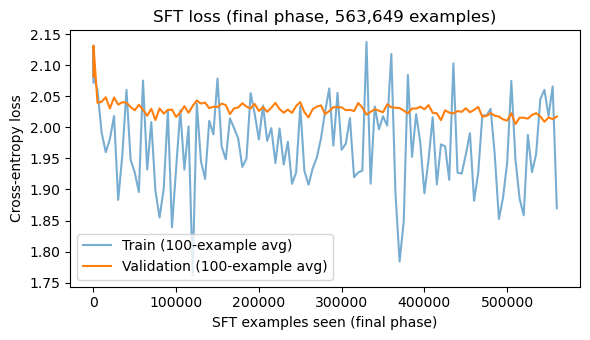

In [49]:
import csv
import matplotlib.pyplot as plt

steps, train_l, val_l = [], [], []
with open("sft_losses.csv") as f:
    for row in csv.reader(f):
        steps.append(int(row[0])); train_l.append(float(row[1])); val_l.append(float(row[2]))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(steps, train_l, label="Train (100-example avg)", alpha=0.6)
ax.plot(steps, val_l, label="Validation (100-example avg)")
ax.set_xlabel("SFT examples seen (final phase)")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("SFT loss (final phase, 563,649 examples)")
ax.legend()
plt.tight_layout()
plt.savefig("sft_loss_curve.png", dpi=150)
plt.show()

In [ ]:
chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load("my-finetuned-gpt.pth", map_location="cpu", weights_only=True))
chat_model.to(device).eval()

In [ ]:
model.eval()                      # <-- ADD this line

torch.manual_seed(123)

for entry in test_data[:3]:
    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=GPT_CONFIG_163M["context_length"],
        temperature=0.7,          # <-- ADD this line
        top_k=40,                 # <-- ADD this line
        eos_id=50256
    )

    generated_text = token_ids_to_text(token_ids, tokenizer)

    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )

    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

In [ ]:
# torch.manual_seed(123)

# for entry in test_data[:3]:
#     input_text = format_input(entry)

#     token_ids = generate(
#         model=model,
#         idx=text_to_token_ids(input_text, tokenizer).to(device),
#         max_new_tokens=256,
#         context_size=GPT_CONFIG_163M["context_length"],
#         eos_id=50256
#     )

#     generated_text = token_ids_to_text(token_ids, tokenizer)

#     response_text = (
#         generated_text[len(input_text):]
#         .replace("### Response:", "")
#         .strip()
#     )

#     print(input_text)
#     print(f"\nCorrect response:\n>> {entry['output']}")
#     print(f"\nModel response:\n>> {response_text.strip()}")
#     print("-------------------------------------")

In [ ]:
import json
from tqdm import tqdm

num_test_examples = 10
test_results = []

model.eval()

for i, entry in enumerate(
    tqdm(test_data[:num_test_examples], total=min(num_test_examples, len(test_data)))
):
    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=GPT_CONFIG_163M["context_length"],
        eos_id=50256
    )

    generated_text = token_ids_to_text(token_ids, tokenizer)

    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )

    entry["model_response"] = response_text   # <-- NEW LINE

    result = dict(entry)
    result["model_response"] = response_text
    test_results.append(result)

with open(
    "instruction_before_sft_sample.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(test_results, file, indent=4, ensure_ascii=False)

print("Examples evaluated:", len(test_results))
print("Baseline responses saved to instruction_before_sft_sample.json")

100%|██████████| 10/10 [00:27<00:00,  2.73s/it]

Examples evaluated: 10
Baseline responses saved to instruction_before_sft_sample.json


In [202]:

# Save your own fine-tuned GPT model
torch.save(model.state_dict(), "my-finetuned-gpt.pth")

print("Model saved as my-finetuned-gpt.pth")


Model saved as my-finetuned-gpt.pth


In [ ]:
chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load("my-finetuned-gpt.pth", map_location="cpu", weights_only=True))
chat_model.to(device).eval()

generated with temperature 0.7, top-k 40 from the final 163M SFT model. Not cherry-picked. The model produces fluent text but often gets facts wrong, as expected at this scale.

In [ ]:
def ask(text, max_new_tokens=150, temperature=0.7, top_k=40):
    prompt = (
    format_input({"instruction": text, "input": ""})
    + "\n\n### Response:\n"
)
    ids = text_to_token_ids(prompt, tokenizer).to(chat_device)
    out = generate(chat_model, ids, max_new_tokens=max_new_tokens,
                   context_size=chat_model.pos_emb.weight.shape[0],
                   temperature=temperature, top_k=top_k, eos_id=50256)
    reply = tokenizer.decode(out[0, ids.shape[1]:].tolist())
    print(reply.replace("### Response:", "").split("### Instruction")[0].strip())

ask("What is the capital of France?")
ask("Explain what a Python dictionary is.")
ask("What is the difference between AI and machine learning?")

P.S. The capital of France is Paris.
A Python dictionary is a collection of unique elements from a set, and is a concise and easily readable way to access and modify the original data. It provides a collection of values and lists, but it's a limited collection and may not always preserve the original data.

Here is a simple function to extract the values of a given key from a dictionary:

```python
def get_key_value(dictionary, key, value):
    return set(dictionary)
```

This function initializes a set of unique values to store the keys. It then sets the values of the dictionary to set and returns the dictionary with the value of the key. If the key is a dictionary, the
AI and machine learning are both cognitive and machine learning algorithms used to learn from their natural intelligence data. The primary difference between them lies in the nature of their algorithms and the types of training and testing they have in demand.

Artificial intelligence (AI) is a field of study that focu

In [ ]:
import os, time, shutil

print("model.pth last saved:", time.ctime(os.path.getmtime("model.pth")))

shutil.copy("model.pth", "chat_ckpt.pth")

CKPT = "chat_ckpt.pth"
chat_device = "cpu"          # keeps the GPU free for fine-tuning

chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load(CKPT, map_location=chat_device))
chat_model.to(chat_device)
chat_model.eval()
print("Loaded:", CKPT)

model.pth last saved: Tue Oct 20 17:41:28 2026
Loaded: chat_ckpt.pth


In [218]:
chat_model.eval()
with torch.no_grad():
    print(calc_loss_loader(val_loader, chat_model, device, num_batches=200))

2.005114067941904


In [ ]:
import torch
import ipywidgets as widgets
from IPython.display import display

# 1) Load the latest fine-tuned weights
CKPT = "my-finetuned-gpt.pth"
chat_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load(CKPT, map_location=chat_device, weights_only=True))
chat_model.to(chat_device)
chat_model.eval()
print("Loaded:", CKPT, "on", chat_device)


# 2) Reply function (same prompt format as training + light repetition penalty)
def generate_reply(text, max_new_tokens=200, temperature=0.7, top_k=40, rep_penalty=1.2):
    prompt = format_input({"instruction": text, "input": ""}) + "\n\n### Response:\n"
    ids = text_to_token_ids(prompt, tokenizer).to(chat_device)
    start = ids.shape[1]
    ctx = chat_model.pos_emb.weight.shape[0]

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits = chat_model(ids[:, -ctx:])[:, -1, :].float()

            # discourage repeating tokens already generated
            for t in set(ids[0, start:].tolist()):
                v = logits[0, t]
                logits[0, t] = v / rep_penalty if v > 0 else v * rep_penalty

            # top-k + temperature sampling
            top_vals, _ = torch.topk(logits, top_k)
            logits = torch.where(logits < top_vals[:, -1:], torch.full_like(logits, float("-inf")), logits)
            probs = torch.softmax(logits / temperature, dim=-1)
            nxt = torch.multinomial(probs, num_samples=1)

            if nxt.item() == 50256:   # <|endoftext|>
                break
            ids = torch.cat((ids, nxt), dim=1)

    reply = tokenizer.decode(ids[0, start:].tolist())
    return reply.split("### Instruction")[0].strip()


# 3) Chat box
log = widgets.Output()
box = widgets.Text(placeholder="Type a message and press Enter",
                   layout=widgets.Layout(width="80%"))
btn = widgets.Button(description="Send", button_style="primary")

def on_send(_=None):
    text = box.value.strip()
    if not text:
        return
    box.value = ""
    with log:
        print("You:", text)
        print("Bot:", generate_reply(text), "\n")

btn.on_click(on_send)
box.on_submit(on_send)
display(log, widgets.HBox([box, btn]))

In [43]:

import torch
import math
import torch.nn.functional as F

def calculate_perplexity(model, data_loader, device):
    model.eval()

    total_nll = 0.0
    total_tokens = 0

    with torch.inference_mode():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            # Predict the next token at every position
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
                logits = model(inputs)

            # Sum cross-entropy over valid target tokens
            loss_sum = F.cross_entropy(
                logits.float().reshape(-1, logits.size(-1)),
                targets.reshape(-1),
                ignore_index=-100,
                reduction="sum"
            )

            # Exclude padding positions marked -100
            valid_tokens = (targets != -100).sum().item()

            total_nll += loss_sum.item()
            total_tokens += valid_tokens

    if total_tokens == 0:
        raise ValueError("No valid validation tokens found.")

    average_loss = total_nll / total_tokens
    perplexity = math.exp(average_loss)

    return average_loss, perplexity


# Evaluate your fine-tuned model
loss, ppl = calculate_perplexity(
    chat_model,
    val_loader,
    device
)

print(f"Validation cross-entropy: {loss:.4f}")
print(f"Validation perplexity: {ppl:.4f}")


Validation cross-entropy: 2.0373
Validation perplexity: 7.6699


In [254]:
torch.save(chat_model.state_dict(), "chat_model_final.pth")
print("saved")

saved


In [66]:
import json, re, urllib.request, psutil
import numpy as np
from tqdm import tqdm

OLLAMA_MODEL = "llama3.1:8b"
OLLAMA_URL = "http://localhost:11434/api/chat"

OLLAMA_OK = any("ollama" in (p.info["name"] or "").lower()
                for p in psutil.process_iter(["name"]))
print("Ollama running:", OLLAMA_OK)
if not OLLAMA_OK:
    print("Warning: Ollama not running, judge scoring will be skipped.")

def query_model(prompt, model=OLLAMA_MODEL, url=OLLAMA_URL):
    data = {
        "model": model,
        "messages": [{"role": "user", "content": prompt}],
        "stream": False,
        "options": {"seed": 123, "temperature": 0, "num_ctx": 4096},
    }
    req = urllib.request.Request(
        url, data=json.dumps(data).encode("utf-8"), method="POST",
        headers={"Content-Type": "application/json"},
    )
    with urllib.request.urlopen(req) as resp:
        return json.loads(resp.read())["message"]["content"]

Ollama running: True


In [ ]:
# Load the fine-tuned weights fresh, so this cell doesn't depend on earlier state
chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load("my-finetuned-gpt.pth", map_location="cpu", weights_only=True))
chat_model.to(device).eval()

N_EVAL = 100
rows = []
for entry in tqdm(test_data[:N_EVAL], desc="generate"):
    prompt = format_input(entry)
    ids = text_to_token_ids(prompt, tokenizer).to(device)
    out = generate(chat_model, ids, max_new_tokens=256,
                   context_size=GPT_CONFIG_163M["context_length"], eos_id=50256)
    resp = token_ids_to_text(out, tokenizer)[len(prompt):].replace("### Response:", "").strip()
    rows.append({"instruction": entry["instruction"], "input": entry["input"],
                 "reference": entry["output"], "response": resp})

scores = []
if OLLAMA_OK:
    for r in tqdm(rows, desc="judge"):
        p = (f"Given the input `{format_input({'instruction': r['instruction'][:800], 'input': r['input']})}` "
             f"and correct output `{r['reference'][:1500]}`, "
             f"score the model response `{r['response'][:1500]}` "
             f"on a scale from 0 to 100, where 100 is the best score. "
             f"Respond with the integer number only.")
        m = re.search(r"\d+", query_model(p))
        r["score"] = min(int(m.group()), 100) if m else None
        if r["score"] is not None:
            scores.append(r["score"])
    print(f"Judge (Llama 3.1 8B), after SFT: n={len(scores)}, mean={np.mean(scores):.1f}, std={np.std(scores):.1f}")
else:
    print("Ollama not running, judge skipped.")

with open("instruction_after_sft_sample.json", "w", encoding="utf-8") as f:
    json.dump(rows, f, indent=2, ensure_ascii=False)
print("Saved instruction_after_sft_sample.json")

judge: 100%|██████████| 100/100 [04:26<00:00,  2.67s/it]

Judge (Llama 3.1 8B), after SFT: n=100, mean=37.6, std=39.1
Saved instruction_after_sft_sample.json


In [1]:
import math
import torch
import torch.nn as nn
import tiktoken

# ---------- Config (must match training) ----------
GPT_CONFIG_163M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

# ---------- Model ----------
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, _ = x.shape
        keys = self.W_key(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        queries = self.W_query(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        values = self.W_value(x).view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        context_vec = torch.nn.functional.scaled_dot_product_attention(
            queries, keys, values,
            dropout_p=self.dropout.p if self.training else 0.0,
            is_causal=True,
        ).transpose(1, 2)
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        return self.out_proj(context_vec)


class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        return torch.nn.functional.layer_norm(
            x, self.scale.shape, self.scale, self.shift, self.eps
        )


class GELU(nn.Module):
    def forward(self, x):
        return torch.nn.functional.gelu(x, approximate="tanh")


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"], d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"], dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"],
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.drop_shortcut(self.att(self.norm1(x))) + shortcut
        shortcut = x
        x = self.drop_shortcut(self.ff(self.norm2(x))) + shortcut
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        _, seq_len = in_idx.shape
        x = self.tok_emb(in_idx) + self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        return self.out_head(x)


# ---------- Tokenizer helpers ----------
tokenizer = tiktoken.get_encoding("gpt2")

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
    return torch.tensor(encoded).unsqueeze(0)

def format_input(entry):
    instruction_text = (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )
    input_text = f"\n\n### Input:\n{entry['input']}" if entry.get("input") else ""
    return instruction_text + input_text

# ---------- Load fine-tuned weights ----------
CKPT = "my-finetuned-gpt.pth"
chat_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(torch.load(CKPT, map_location=chat_device, weights_only=True))
chat_model.to(chat_device).eval()
print("Loaded:", CKPT, "on", chat_device)

# ---------- Reply function (used by the Gradio cell) ----------
def generate_reply(text, max_new_tokens=200, temperature=0.7, top_k=40, rep_penalty=1.2):
    prompt = format_input({"instruction": text, "input": ""}) + "\n\n### Response:\n"
    ids = text_to_token_ids(prompt, tokenizer).to(chat_device)
    start = ids.shape[1]
    ctx = chat_model.pos_emb.weight.shape[0]

    with torch.no_grad():
        for _ in range(max_new_tokens):
            logits = chat_model(ids[:, -ctx:])[:, -1, :].float()

            # discourage repeating tokens already generated
            for t in set(ids[0, start:].tolist()):
                v = logits[0, t]
                logits[0, t] = v / rep_penalty if v > 0 else v * rep_penalty

            # top-k + temperature sampling
            top_vals, _ = torch.topk(logits, top_k)
            logits = torch.where(
                logits < top_vals[:, -1:], torch.full_like(logits, float("-inf")), logits
            )
            probs = torch.softmax(logits / temperature, dim=-1)
            nxt = torch.multinomial(probs, num_samples=1)

            if nxt.item() == 50256:  # <|endoftext|>
                break
            ids = torch.cat((ids, nxt), dim=1)

    reply = tokenizer.decode(ids[0, start:].tolist())
    return reply.split("### Instruction")[0].strip()

# quick sanity check
print(generate_reply("What is the capital of France?", max_new_tokens=40))

Loaded: my-finetuned-gpt.pth on cuda
The capital of France is Paris. It's a city known for its historical landmarks, cultural significance, and historical significance, and it's one of the greatest places in Rome.


In [5]:
CKPT = "my-finetuned-gpt.pth"

chat_model = GPTModel(GPT_CONFIG_163M)
chat_model.load_state_dict(
    torch.load(CKPT, map_location=chat_device, weights_only=True)
)
chat_model.to(chat_device)
chat_model.eval()
model = chat_model

In [8]:
import torch, tiktoken
import matplotlib.pyplot as plt

tok = tiktoken.get_encoding("gpt2")
device = next(model.parameters()).device
model.eval()

def build(country):
    return (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\ncapital of {country.lower()}"
        "\n\n### Response:\n"
        f"The capital of {country} is"
    )

In [9]:
def top_k(prompt, k=10):
    ids = torch.tensor([tok.encode(prompt)], device=device)
    with torch.no_grad():
        logits = model(ids)[0, -1]
    top = logits.softmax(-1).topk(k)
    print(repr(prompt[-40:]))
    for prob, i in zip(top.values, top.indices):
        print(f"   {tok.decode([i.item()])!r:14} {prob.item():.3f}")
    return logits

answers = {"France": " Paris", "Italy": " Rome", "India": " Delhi",
           "Germany": " Berlin", "Japan": " Tokyo"}
for c in answers.values():
    assert len(tok.encode(c)) == 1, f"{c!r} is multi-token"

paris = tok.encode(" Paris")[0]
for country, city in answers.items():
    logits = top_k(build(country))
    cid = tok.encode(city)[0]
    print(f"   >>> logit({city.strip()}) - logit(Paris) = {(logits[cid] - logits[paris]).item():.2f}\n")

'\n\n### Response:\nThe capital of France is'
   ' Paris'       0.823
   ' France'      0.024
   ' the'         0.018
   ' "'           0.007
   " '"           0.004
   ' E'           0.004
   ' Lou'         0.002
   ' a'           0.002
   ' ['           0.002
   ' French'      0.002
   >>> logit(Paris) - logit(Paris) = 0.00

'y\n\n### Response:\nThe capital of Italy is'
   ' Paris'       0.539
   ' Rome'        0.049
   ' the'         0.029
   ' Italy'       0.025
   ' Florence'    0.018
   ' "'           0.017
   " '"           0.010
   ' P'           0.008
   ' France'      0.008
   ' ['           0.005
   >>> logit(Rome) - logit(Paris) = -2.39

'a\n\n### Response:\nThe capital of India is'
   ' Paris'       0.330
   ' the'         0.052
   ' "'           0.032
   ' India'       0.027
   " '"           0.016
   ' a'           0.012
   ' New'         0.011
   ' ['           0.008
   ' May'         0.006
   ' China'       0.005
   >>> logit(Delhi) - logit(Paris) = -9.92

'\n### Respo

metric on source (Italy): -2.39
metric on base   (France): -6.48


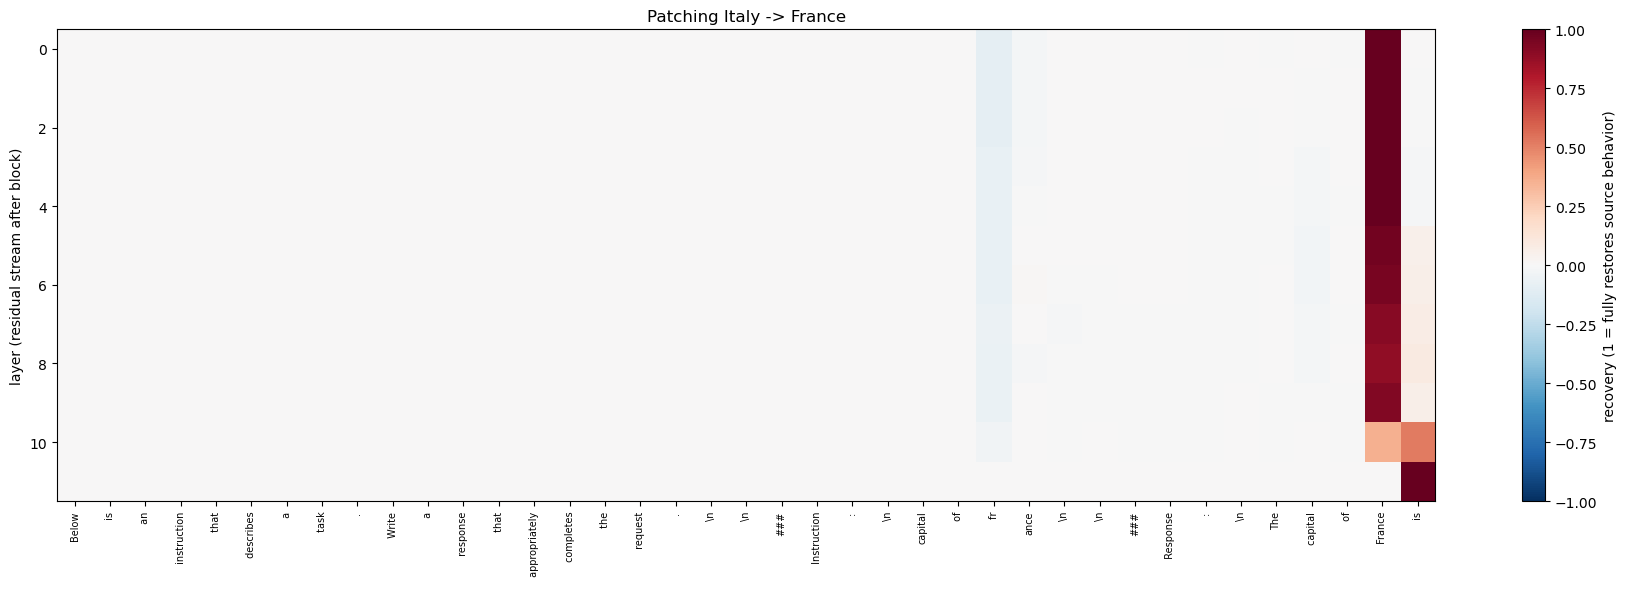

In [ ]:
SRC, BASE = "Italy", "France"           
SRC_ANS, BASE_ANS = " Rome", " Paris"

def ids(c):
    return torch.tensor([tok.encode(build(c))], device=device)

src_ids, base_ids = ids(SRC), ids(BASE)
assert src_ids.shape == base_ids.shape, "prompts must tokenize to the same length"
T = src_ids.shape[1]
for a in (SRC_ANS, BASE_ANS):
    assert len(tok.encode(a)) == 1, f"{a!r} is multi-token"
src_t, base_t = tok.encode(SRC_ANS)[0], tok.encode(BASE_ANS)[0]

def metric(logits):                      
    return (logits[0, -1, src_t] - logits[0, -1, base_t]).item()

blocks = model.trf_blocks                
L = len(blocks)

# cache residual stream after every block on the SOURCE prompt
cache, hooks = {}, []
for l, b in enumerate(blocks):
    hooks.append(b.register_forward_hook(
        lambda m, i, o, l=l: cache.__setitem__(l, o.detach().clone())))
with torch.no_grad():
    m_src = metric(model(src_ids))
for h in hooks: h.remove()

with torch.no_grad():
    m_base = metric(model(base_ids))

print(f"metric on source ({SRC}): {m_src:.2f}")
print(f"metric on base   ({BASE}): {m_base:.2f}")
assert abs(m_src - m_base) > 0.5, "no gap between prompts -> nothing to patch"

# patch one (layer, position) at a time into the BASE run
def patched_metric(l, pos):
    def hook(m, i, o):
        o = o.clone()
        o[:, pos] = cache[l][:, pos]
        return o                         # returning is what makes the patch take effect
    h = blocks[l].register_forward_hook(hook)
    with torch.no_grad():
        val = metric(model(base_ids))
    h.remove()
    return val

grid = torch.zeros(L, T)
for l in range(L):
    for p in range(T):
        grid[l, p] = (patched_metric(l, p) - m_base) / (m_src - m_base)

# heatmap
labels = [tok.decode([t]).replace("\n", "\\n") for t in base_ids[0].tolist()]
plt.figure(figsize=(18, 6))
plt.imshow(grid.numpy(), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="recovery (1 = fully restores source behavior)")
plt.xticks(range(T), labels, rotation=90, fontsize=7)
plt.ylabel("layer (residual stream after block)")
plt.title(f"Patching {SRC} -> {BASE}")
plt.tight_layout(); plt.savefig("patching_heatmap.png", dpi=150); plt.show()

In [11]:
diff = (src_ids[0] != base_ids[0]).nonzero().flatten().tolist()
print("differing positions:", diff, [tok.decode([base_ids[0, p].item()]) for p in diff])
instr_pos = diff[:-1]      # country tokens in the instruction
resp_pos  = diff[-1]       # country token in the response prefix

def patch_many(l, positions):
    def hook(m, i, o):
        o = o.clone()
        for p in positions:
            o[:, p] = cache[l][:, p]
        return o
    h = blocks[l].register_forward_hook(hook)
    with torch.no_grad():
        val = metric(model(base_ids))
    h.remove()
    return (val - m_base) / (m_src - m_base)

print("layer | instruction (all tokens) | response country | both")
for l in range(L):
    print(f"{l:5d} | {patch_many(l, instr_pos):24.2f} | {patch_many(l, [resp_pos]):16.2f} | {patch_many(l, instr_pos + [resp_pos]):.2f}")

differing positions: [26, 27, 37] [' fr', 'ance', ' France']
layer | instruction (all tokens) | response country | both
    0 |                    -0.10 |             1.05 | 1.00
    1 |                    -0.09 |             1.05 | 1.00
    2 |                    -0.09 |             1.05 | 1.01
    3 |                    -0.07 |             1.04 | 1.02
    4 |                    -0.06 |             1.04 | 1.03
    5 |                    -0.07 |             0.96 | 0.96
    6 |                    -0.06 |             0.95 | 0.96
    7 |                    -0.06 |             0.91 | 0.92
    8 |                    -0.07 |             0.89 | 0.88
    9 |                    -0.07 |             0.93 | 0.92
   10 |                    -0.04 |             0.36 | 0.34
   11 |                     0.00 |             0.00 | 0.00


In [12]:
pairs = {"Italy": " Rome", "Germany": " Berlin", "Japan": " Tokyo", "India": " Delhi"}
BASE, BASE_ANS = "France", " Paris"
base_ids = ids(BASE)
base_t = tok.encode(BASE_ANS)[0]

def run_pair(SRC, ANS):
    s_ids = ids(SRC)
    if s_ids.shape != base_ids.shape or len(tok.encode(ANS)) != 1:
        print(f"\nskip {SRC} (token length mismatch)"); return
    s_t = tok.encode(ANS)[0]
    m = lambda lg: (lg[0, -1, s_t] - lg[0, -1, base_t]).item()

    cache, hooks = {}, []
    for l, b in enumerate(blocks):
        hooks.append(b.register_forward_hook(
            lambda mod, i, o, l=l: cache.__setitem__(l, o.detach().clone())))
    with torch.no_grad(): m_s = m(model(s_ids))
    for h in hooks: h.remove()
    with torch.no_grad(): m_b = m(model(base_ids))

    gap = m_s - m_b
    if abs(gap) < 0.5:
        print(f"\nskip {SRC}: gap {gap:.2f} too small to patch"); return

    diff = (s_ids[0] != base_ids[0]).nonzero().flatten().tolist()
    instr, resp = diff[:-1], [diff[-1]]

    def rec(l, pos):
        def hook(mod, i, o):
            o = o.clone()
            for p in pos: o[:, p] = cache[l][:, p]
            return o
        h = blocks[l].register_forward_hook(hook)
        with torch.no_grad(): v = m(model(base_ids))
        h.remove()
        return (v - m_b) / gap

    print(f"\n{SRC}: gap = {gap:.2f}")
    print("layer | instruction | response country")
    for l in [0, 4, 8, 9, 10, 11]:
        print(f"{l:5d} | {rec(l, instr):11.2f} | {rec(l, resp):.2f}")

for s, a in pairs.items():
    run_pair(s, a)


Italy: gap = 4.09
layer | instruction | response country
    0 |       -0.10 | 1.05
    4 |       -0.06 | 1.04
    8 |       -0.07 | 0.89
    9 |       -0.07 | 0.93
   10 |       -0.04 | 0.36
   11 |        0.00 | 0.00

skip Germany (token length mismatch)

Japan: gap = 7.23
layer | instruction | response country
    0 |        0.30 | 0.87
    4 |        0.29 | 0.85
    8 |        0.25 | 0.69
    9 |        0.25 | 0.70
   10 |        0.07 | 0.19
   11 |        0.00 | 0.00

India: gap = 3.85
layer | instruction | response country
    0 |        0.01 | 0.99
    4 |        0.02 | 0.99
    8 |       -0.01 | 0.85
    9 |       -0.04 | 0.80
   10 |       -0.02 | 0.23
   11 |        0.00 | 0.00
